Device: cuda
Jumlah kelas: 81
Font total: 28 | latih: 23 | uji (tidak dilihat): 5
Keluarga font khusus uji: ['LiberationMono', 'cmr10', 'cmtt10']
Contoh teks:
   Kepala Seksi Teknik
   Ahmad, M.Si.
   Lampiran : 2 (dua) berkas
   Batam, 27 Januari 2025
   Keputusan Nomor
   2015. Bersama ini
   sampaikan strategis
   Sehubungan edaran peraturan ruang
   Yth. Kepala Seksi Program dan Siaran
   Hj. Rina


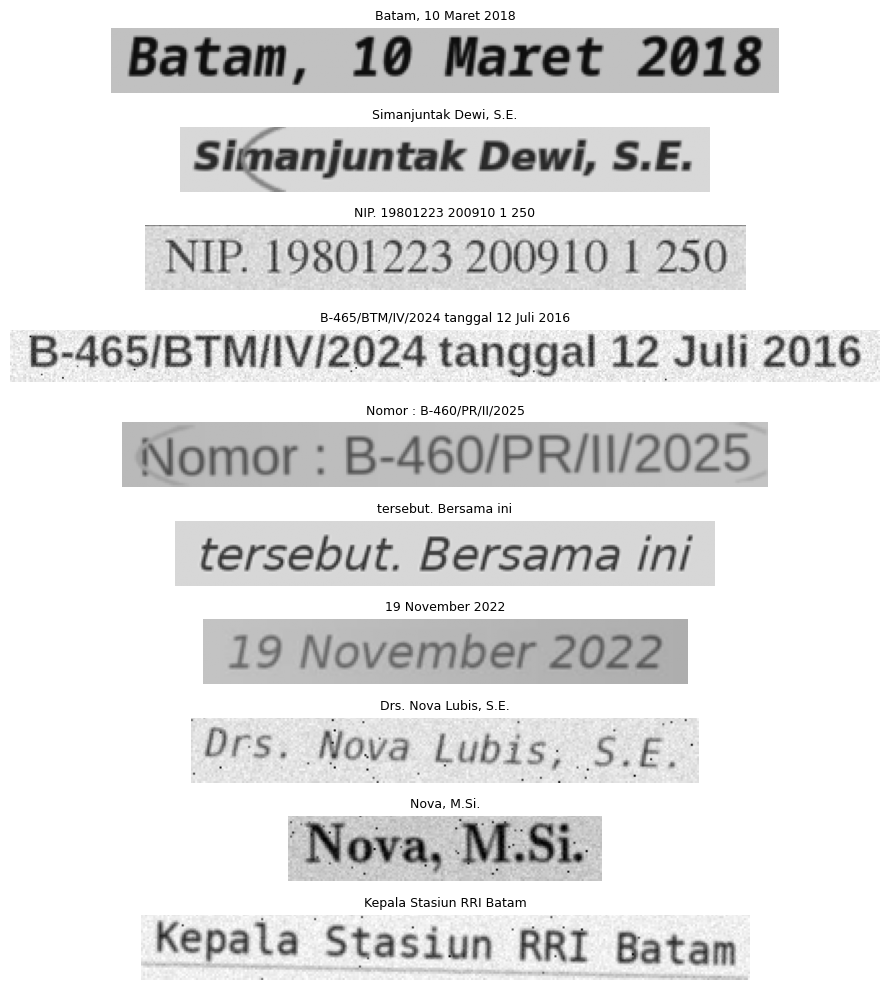

Memuat model awal dari: /kaggle/input/datasets/akundummy12/crnn-best/crnn_best.pth
SEBELUM fine-tune | font dikenal: CER 1.31% WER 8.22% | font baru: CER 1.71% WER 9.72%
Epoch 01/20 | loss 0.0166 | CER dikenal 0.16% | CER font baru 0.20% | WER font baru 1.26% | exact 96.5% | 131s
   -> model terbaik disimpan
Epoch 02/20 | loss 0.0053 | CER dikenal 0.12% | CER font baru 0.17% | WER font baru 1.08% | exact 97.2% | 132s
   -> model terbaik disimpan
Epoch 03/20 | loss 0.0049 | CER dikenal 0.07% | CER font baru 0.11% | WER font baru 0.78% | exact 97.8% | 133s
   -> model terbaik disimpan
Epoch 04/20 | loss 0.0036 | CER dikenal 0.07% | CER font baru 0.11% | WER font baru 0.64% | exact 98.3% | 132s
   -> model terbaik disimpan
Epoch 05/20 | loss 0.0037 | CER dikenal 0.06% | CER font baru 0.11% | WER font baru 0.87% | exact 97.9% | 132s
Epoch 06/20 | loss 0.0039 | CER dikenal 0.04% | CER font baru 0.10% | WER font baru 0.66% | exact 98.0% | 132s
   -> model terbaik disimpan
Epoch 07/20 | loss 

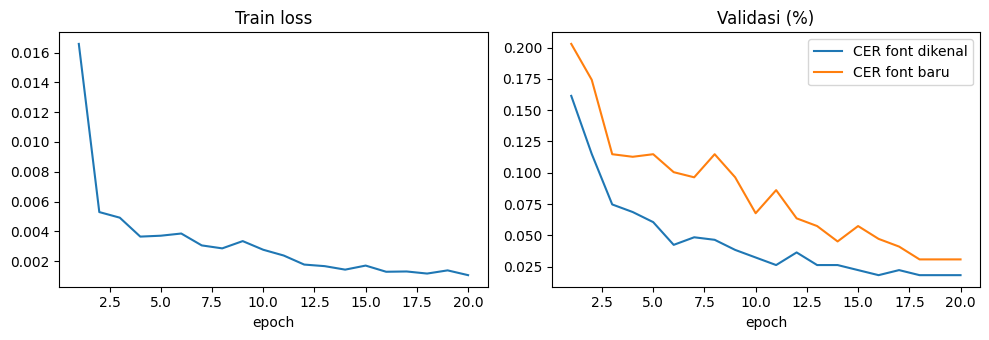

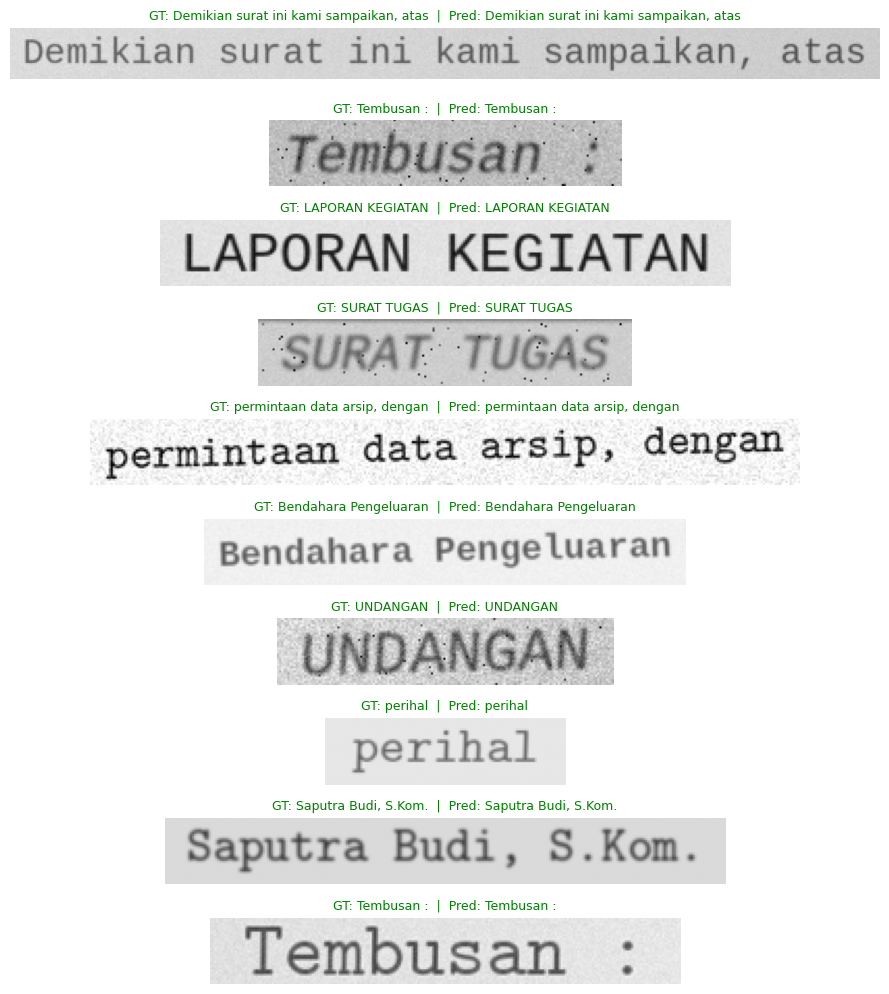

Belum ada gambar di /kaggle/working/real_lines. Siapkan gambar dulu (lihat petunjuk di atas), lalu jalankan cell ini lagi.


In [1]:
# ============================================================
# CELL: 0. Import & konfigurasi  (FINE-TUNE BAHASA INDONESIA)
# ============================================================
# Syarat: file crnn_best.pth (hasil training Inggris) tersedia di
#   - /kaggle/input/<nama-dataset>/crnn_best.pth  (upload sebagai Dataset), atau
#   - /kaggle/working/crnn_best.pth
# Aktifkan GPU: Settings -> Accelerator -> GPU

import os, sys, io, re, glob, csv, random, string, time
import numpy as np
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from PIL import Image, ImageDraw, ImageFont, ImageFilter, ImageOps
import matplotlib
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

# ---------- KONFIGURASI ----------
IMG_H = 32
MAX_LEN = 48          # baris surat lebih panjang dari versi Inggris
MAX_W = 768
BATCH_SIZE = 96
EPOCHS = 20
TRAIN_SIZE = 50000
VAL_SIZE = 2000
LR = 3e-4             # lebih kecil dari training awal (ini fine-tuning)
NUM_WORKERS = 4
EN_RATIO = 0.15       # porsi data Inggris dicampur supaya model tidak "lupa"
OUT_DIR = "/kaggle/working"

# (Opsional) file teks bahasa Indonesia, 1 kalimat per baris, untuk memperkaya data.
# Contoh: upload corpus sebagai Dataset lalu isi path-nya. Kosongkan kalau tidak ada.
CORPUS_PATH = ""

# HARUS SAMA PERSIS dengan charset training Inggris
CHARS = string.ascii_letters + string.digits + ".,:;-/()'\"&%#@!?+ "
BLANK = 0
char2idx = {c: i + 1 for i, c in enumerate(CHARS)}
idx2char = {i + 1: c for i, c in enumerate(CHARS)}
NUM_CLASSES = len(CHARS) + 1
print("Jumlah kelas:", NUM_CLASSES)

# ============================================================
# CELL: 1. Font (dengan filter) + pemisahan font latih / font uji
# ============================================================

REF_FONT = ImageFont.truetype(
    os.path.join(os.path.dirname(matplotlib.__file__), "mpl-data/fonts/ttf/DejaVuSans.ttf"), 40)
ALNUM = string.ascii_letters + string.digits

def norm_glyph(f, ch):
    im = Image.new("L", (80, 80), 0)
    ImageDraw.Draw(im).text((10, 5), ch, font=f, fill=255)
    bb = im.getbbox()
    if bb is None:
        return None
    return np.asarray(im.crop(bb).resize((24, 24), Image.BILINEAR), dtype=np.float32) / 255

REF_GLYPHS = {c: norm_glyph(REF_FONT, c) for c in ALNUM}

def font_is_good(path, min_sim=0.45):
    try:
        f = ImageFont.truetype(path, 40)
    except Exception:
        return False

    def glyph(ch):
        im = Image.new("L", (64, 64), 0)
        ImageDraw.Draw(im).text((8, 4), ch, font=f, fill=255)
        return im.tobytes()

    blank = Image.new("L", (64, 64), 0).tobytes()
    notdef = glyph("\uFFFF")
    masks = {}
    for ch in CHARS:
        if ch == " ":
            continue
        g = glyph(ch)
        if g == blank or g == notdef:
            return False
        masks[ch] = g
    if len(set(masks.values())) < len(masks) - 3:
        return False
    sims = []
    for c, ref in REF_GLYPHS.items():
        g = norm_glyph(f, c)
        if g is None:
            return False
        a, b = g - g.mean(), ref - ref.mean()
        sims.append((a * b).sum() / (np.sqrt((a * a).sum() * (b * b).sum()) + 1e-8))
    return float(np.mean(sims)) >= min_sim

def find_fonts():
    paths = glob.glob("/usr/share/fonts/**/*.ttf", recursive=True)
    paths += glob.glob(os.path.join(os.path.dirname(matplotlib.__file__), "mpl-data/fonts/ttf/*.ttf"))
    good, seen = [], set()
    for p in sorted(set(paths)):
        name = os.path.basename(p)
        if name in seen:            # buang duplikat nama file
            continue
        if font_is_good(p):
            seen.add(name); good.append(p)
    return good

ALL_FONTS = find_fonts()
assert len(ALL_FONTS) > 0, "Tidak ada font ditemukan"

# Pisahkan per "keluarga" font: sebagian khusus untuk uji (tidak pernah dilihat saat training)
def family(p):
    return re.split(r"[-_.]", os.path.basename(p))[0]

fams = sorted(set(family(p) for p in ALL_FONTS))
random.Random(7).shuffle(fams)
n_hold = max(1, len(fams) // 4) if len(fams) >= 4 else 0
HOLD = set(fams[:n_hold])
TRAIN_FONTS = [p for p in ALL_FONTS if family(p) not in HOLD]
VAL_FONTS = [p for p in ALL_FONTS if family(p) in HOLD] or TRAIN_FONTS
print("Font total:", len(ALL_FONTS), "| latih:", len(TRAIN_FONTS), "| uji (tidak dilihat):", len(VAL_FONTS))
print("Keluarga font khusus uji:", sorted(HOLD))

# ============================================================
# CELL: 2. Generator teks surat bahasa Indonesia
# ============================================================

KATA = """yang dan di untuk dengan pada dari dalam akan kepada sebagai oleh ini itu atau adalah tidak dapat telah sudah
kami kita saya bapak ibu mohon harap segera berkaitan sehubungan menindaklanjuti pelaksanaan kegiatan rapat koordinasi
undangan pemberitahuan permohonan laporan pertanggungjawaban anggaran keuangan penyiaran program siaran radio stasiun
kantor pegawai pejabat pimpinan bagian bidang seksi tata usaha umum kepegawaian perlengkapan arsip dokumen surat
keputusan edaran tugas perintah perjalanan dinas cuti tahunan kenaikan pangkat gaji berkala tunjangan kinerja evaluasi
monitoring sosialisasi pelatihan bimbingan teknis workshop seminar peserta narasumber tempat waktu hari tanggal pukul
ruang aula gedung jalan kota provinsi kepulauan riau batam indonesia republik negara pemerintah daerah pusat nasional
lembaga publik masyarakat informasi komunikasi digital teknologi sistem aplikasi data layanan pengelolaan pengadaan
barang jasa peralatan pemeliharaan perbaikan inventarisasi aset kendaraan bangunan sarana prasarana personel tim
panitia pelaksana penanggung jawab ketua sekretaris anggota bendahara staf kepala direktur manajer koordinator
verifikasi validasi pengesahan persetujuan penandatanganan pengiriman penerimaan pengumuman lampiran tembusan perihal
nomor sifat penting rahasia biasa demikian atas perhatian kerja sama terima kasih hormat tahun bulan triwulan semester
periode target realisasi hasil rencana strategis kebijakan peraturan undang pasal ayat ketentuan sesuai berdasarkan
mengingat menimbang memutuskan menetapkan pertama kedua ketiga keempat berlaku sejak ditetapkan dilaksanakan
disampaikan diharapkan diminta dimohon menghadiri mengikuti menyiapkan menyampaikan melaporkan melaksanakan memberikan
mengajukan menerima menyetujui mengevaluasi menyelenggarakan tersebut berikut terlampir dimaksud terkait khususnya
lingkungan antara setiap semua seluruh beberapa lainnya maupun serta bahwa karena sehingga namun tetapi apabila jika
agar supaya guna bagi tentang terhadap melalui selama setelah sebelum hingga sampai pegawai honorer kontrak
perencanaan penyusunan pengendalian pengawasan pembinaan pengembangan peningkatan kualitas konten berita warta
musik hiburan budaya pendidikan olahraga kesehatan lingkungan hidup ekonomi pariwisata pemuda perempuan anak""".split()

NAMA = """Ahmad Budi Siti Dewi Rina Agus Eko Hendra Yulia Fajar Rizky Nur Indah Wahyu Dian Lestari Putra Sari Andi Joko
Slamet Bambang Muhammad Abdul Sri Ratna Taufik Hasan Rahmat Yusuf Ika Maya Fitri Arif Dedi Irfan Lina Mega Nova Rudi
Santoso Wijaya Pratama Hidayat Saputra Kurniawan Nugroho Setiawan Lubis Siregar Nasution Harahap Simanjuntak""".split()

JABATAN = ["Kepala Stasiun RRI Batam", "Kepala Bagian Umum", "Kepala Seksi Program dan Siaran",
           "Kepala Sub Bagian Tata Usaha", "Sekretaris", "Bendahara Pengeluaran", "Pejabat Pembuat Komitmen",
           "Kepala Seksi Teknik", "Staf Kepegawaian", "Pranata Humas Ahli Muda", "Arsiparis Terampil",
           "Kepala Bidang Layanan", "Direktur Utama LPP RRI", "Kepala Bagian Keuangan"]
PERIHAL = ["Undangan Rapat Koordinasi", "Permohonan Cuti Tahunan", "Laporan Kegiatan Triwulan II",
           "Pemberitahuan Jadwal Siaran", "Penyampaian Dokumen Anggaran", "Permohonan Data Kepegawaian",
           "Surat Perintah Perjalanan Dinas", "Usulan Kenaikan Pangkat", "Pemeliharaan Peralatan Siaran",
           "Evaluasi Kinerja Pegawai", "Permohonan Izin Peliputan", "Penyampaian Laporan Keuangan",
           "Undangan Sosialisasi Program", "Permintaan Data Arsip", "Pengadaan Barang dan Jasa"]
TEMPAT = ["Aula Kantor RRI Batam", "Ruang Rapat Lantai 2", "Studio Utama", "Gedung Serbaguna", "Ruang Pimpinan"]
ALAMAT = ["Jl. Engku Putri No. 1, Batam Centre", "Jl. Raja Ali Haji No. 12, Batam", "Kota Batam, Kepulauan Riau",
          "Jl. Jenderal Sudirman No. 25, Batam", "Kawasan Batam Centre, Kepulauan Riau"]
HARI = ["Senin", "Selasa", "Rabu", "Kamis", "Jumat", "Sabtu", "Minggu"]
BULAN = ["Januari", "Februari", "Maret", "April", "Mei", "Juni", "Juli", "Agustus",
         "September", "Oktober", "November", "Desember"]
ROMAN = ["I", "II", "III", "IV", "V", "VI", "VII", "VIII", "IX", "X", "XI", "XII"]
KODE = ["RRI", "BTM", "UM", "KP", "PR", "TU", "KU", "TK", "PS"]
ANGKA = ["nol", "satu", "dua", "tiga", "empat", "lima"]
HEADINGS = ["LEMBAGA PENYIARAN PUBLIK", "RADIO REPUBLIK INDONESIA", "STASIUN BATAM", "SURAT KEPUTUSAN",
            "SURAT EDARAN", "SURAT TUGAS", "NOTA DINAS", "BERITA ACARA", "KEPALA STASIUN RRI BATAM",
            "MEMUTUSKAN:", "MENIMBANG:", "MENGINGAT:", "LAPORAN KEGIATAN", "DAFTAR HADIR", "UNDANGAN"]

# Teks tambahan dari file (opsional)
EXT_SENTENCES = []
if CORPUS_PATH and os.path.exists(CORPUS_PATH):
    with open(CORPUS_PATH, encoding="utf-8", errors="ignore") as fh:
        for line in fh:
            line = "".join(c for c in line.strip() if c in CHARS)
            if len(line) >= 20:
                EXT_SENTENCES.append(line)
    print("Kalimat tambahan dari corpus:", len(EXT_SENTENCES))

# Teks Inggris (untuk dicampur) - dari docstring modul Python, tanpa internet
def build_corpus():
    words = set()
    for mod in list(sys.modules.values()):
        doc = getattr(mod, "__doc__", None)
        if isinstance(doc, str):
            for w in doc.split():
                w = "".join(c for c in w if c in CHARS)
                if 1 <= len(w) <= 14:
                    words.add(w)
    return sorted(words)

WORDS_EN = build_corpus()
if len(WORDS_EN) < 500:
    WORDS_EN += ["".join(random.choices(string.ascii_lowercase, k=random.randint(3, 9))) for _ in range(2000)]

def perihal():
    return random.choice(PERIHAL)

def tanggal():
    return "%d %s %d" % (random.randint(1, 31), random.choice(BULAN), random.randint(2015, 2026))

def nomor_surat():
    k = random.random()
    if k < 0.5:
        return "%d/%s/%s/%s/%d" % (random.randint(1, 999), random.choice(KODE), random.choice(KODE),
                                   random.choice(ROMAN), random.randint(2015, 2026))
    if k < 0.8:
        return "B-%d/%s/%s/%d" % (random.randint(1, 999), random.choice(KODE), random.choice(ROMAN),
                                  random.randint(2015, 2026))
    return "SK.%03d/%s/%s/%d" % (random.randint(1, 999), random.choice(KODE), random.choice(ROMAN),
                                 random.randint(2015, 2026))

def nama_orang():
    n = " ".join(random.sample(NAMA, random.randint(1, 2)))
    pre = random.choice(["", "", "Drs. ", "Dr. ", "Ir. ", "H. ", "Hj. "])
    suf = random.choice(["", "", ", S.Sos.", ", S.E.", ", M.Si.", ", M.M.", ", S.Kom.", ", S.H.", ", S.T."])
    return pre + n + suf

def nip():
    return "NIP. %d%02d%02d %d%02d %d %03d" % (random.randint(1960, 1999), random.randint(1, 12),
                                             random.randint(1, 28), random.randint(1990, 2020),
                                             random.randint(1, 12), random.randint(1, 2), random.randint(1, 999))

def uang():
    n = random.randint(10000, 9999999999)
    s = f"{n:,}".replace(",", ".")
    return random.choice(["Rp ", "Rp"]) + s + random.choice([",-", ",00", ""])

def kata(n):
    return " ".join(random.choice(KATA) for _ in range(n))

def header_line():
    sep = random.choice([" : ", ": "])
    k = random.randint(0, 12)
    if k == 0:   t = "Nomor" + sep + nomor_surat()
    elif k == 1: t = "Sifat" + sep + random.choice(["Segera", "Penting", "Biasa", "Rahasia"])
    elif k == 2:
        n = random.randint(1, 5)
        t = "Lampiran" + sep + "%d (%s) berkas" % (n, ANGKA[n])
    elif k == 3: t = "Perihal" + sep + perihal()
    elif k == 4: t = "Yth. " + random.choice(JABATAN)
    elif k == 5: t = "Batam, " + tanggal()
    elif k == 6: t = nama_orang()
    elif k == 7: t = random.choice(JABATAN)
    elif k == 8: t = nip()
    elif k == 9: t = random.choice(ALAMAT)
    elif k == 10: t = random.choice(["Tembusan:", "Tembusan :", "Hormat kami,", "Atas nama pimpinan,"])
    elif k == 11: t = "Hari / Tanggal" + sep + "%s, %s" % (random.choice(HARI), tanggal())
    else:        t = "Tempat" + sep + random.choice(TEMPAT)
    return t

def random_sentence():
    k = random.random()
    if k < 0.12:
        return "Sehubungan dengan %s, dengan ini kami mengundang Bapak/Ibu untuk menghadiri kegiatan tersebut." % perihal().lower()
    if k < 0.24:
        return "Berdasarkan Surat Keputusan Nomor %s tanggal %s tentang %s." % (nomor_surat(), tanggal(), perihal().lower())
    if k < 0.36:
        return "Kegiatan akan dilaksanakan pada hari %s, tanggal %s, pukul %02d.%02d WIB bertempat di %s." % (
            random.choice(HARI), tanggal(), random.randint(7, 16), random.choice([0, 15, 30, 45]), random.choice(TEMPAT))
    if k < 0.44:
        return "Demikian surat ini kami sampaikan, atas perhatian dan kerja sama Bapak/Ibu kami ucapkan terima kasih."
    if k < 0.54:
        return "Mohon %s disampaikan paling lambat tanggal %s." % (perihal().lower(), tanggal())
    if k < 0.62:
        return "Anggaran kegiatan sebesar %s telah dialokasikan untuk %s." % (uang(), kata(random.randint(2, 4)))
    if k < 0.70:
        return "Bersama ini kami sampaikan %s untuk %s." % (kata(random.randint(2, 3)), kata(random.randint(3, 5)))
    s = kata(random.randint(6, 14))
    return s.capitalize() + "."

def fit_line(words, max_len):
    line = ""
    for w in words:
        cand = (line + " " + w) if line else w
        if len(cand) > max_len:
            break
        line = cand
    return line if line else words[0][:max_len]

def body_line():
    if EXT_SENTENCES and random.random() < 0.5:
        words = " ".join(random.choice(EXT_SENTENCES) for _ in range(2)).split()
    else:
        words = " ".join(random_sentence() for _ in range(3)).split()
    start = random.randint(0, max(0, len(words) - 6))
    return fit_line(words[start:], random.randint(18, MAX_LEN))

def random_text_id():
    r = random.random()
    if r < 0.30:   t = header_line()
    elif r < 0.72: t = body_line()
    elif r < 0.80: t = random.choice([nomor_surat(), tanggal(), uang(), nip()])
    elif r < 0.88: t = random.choice(HEADINGS + [perihal().upper()])
    elif r < 0.94: t = nama_orang()
    else:          t = kata(random.randint(1, 5))
    t = "".join(c for c in t if c in char2idx)[:MAX_LEN].strip()
    return t if t else "A"

def random_text_en():
    r = random.random()
    if r < 0.6:
        t = " ".join(random.choice(WORDS_EN) for _ in range(random.randint(1, 4)))
    elif r < 0.8:
        t = "".join(random.choices(string.digits, k=random.randint(2, 12)))
    else:
        t = " ".join(random.choice(WORDS_EN) for _ in range(random.randint(1, 3))).upper()
    t = t[:MAX_LEN].strip()
    return t if t else "A"

print("Contoh teks:")
for _ in range(10):
    print("  ", random_text_id())

# ============================================================
# CELL: 3. Render gambar + augmentasi mirip scan/fotokopi
# ============================================================

def render_text(text, fonts):
    font = ImageFont.truetype(random.choice(fonts), random.randint(24, 44))
    l, t, r, b = font.getbbox(text)
    padx, pady = random.randint(8, 18), random.randint(4, 12)
    w, h = max(r - l, 1) + 2 * padx, max(b - t, 1) + 2 * pady
    bg, fg = random.randint(190, 255), random.randint(0, 90)

    img = Image.new("L", (w, h), bg)
    d = ImageDraw.Draw(img)
    d.text((padx - l, pady - t), text, font=font, fill=fg)

    if random.random() < 0.08:    # lingkaran mirip stempel (samar)
        d.ellipse([random.randint(-w // 4, w // 2), -h // 2, random.randint(w // 2, w + w // 4), h + h // 2],
                  outline=random.randint(110, 170), width=random.randint(2, 4))
    if random.random() < 0.10:    # garis tabel di tepi
        y = random.choice([0, 1, h - 2, h - 1])
        d.line([(0, y), (w, y)], fill=random.randint(60, 140), width=random.randint(1, 2))

    k = random.random()
    if k < 0.12:      # tulisan sedikit lebih tebal
        img = Image.blend(img, img.filter(ImageFilter.MinFilter(3)), random.uniform(0.3, 0.7))
    elif k < 0.24:    # tulisan sedikit lebih tipis (dicampur, supaya goresan tidak hilang)
        img = Image.blend(img, img.filter(ImageFilter.MaxFilter(3)), random.uniform(0.2, 0.4))

    if random.random() < 0.3:     # miring (shear)
        sh = random.uniform(-0.15, 0.15)
        img = img.transform(img.size, Image.AFFINE, (1, sh, -sh * img.height / 2, 0, 1, 0),
                            resample=Image.BICUBIC, fillcolor=bg)
    if random.random() < 0.5:
        img = img.rotate(random.uniform(-1.5, 1.5), resample=Image.BICUBIC, expand=True, fillcolor=bg)
    if random.random() < 0.5:
        img = img.filter(ImageFilter.GaussianBlur(random.uniform(0.3, 1.5)))
    if random.random() < 0.25:    # artefak JPEG
        buf = io.BytesIO()
        img.save(buf, "JPEG", quality=random.randint(25, 85))
        buf.seek(0)
        img = Image.open(buf).convert("L")

    new_w = int(img.width * IMG_H / img.height)
    new_w = min(max(new_w, 32), MAX_W)
    img = img.resize((new_w, IMG_H), random.choice([Image.BILINEAR, Image.BICUBIC, Image.LANCZOS]))

    arr = np.asarray(img, dtype=np.float32).copy()
    if random.random() < 0.6:
        arr = arr + np.random.normal(0, random.uniform(2, 15), arr.shape)
    if random.random() < 0.3:     # bintik fotokopi
        n = random.randint(5, 60)
        xs = np.random.randint(0, arr.shape[1], n)
        ys = np.random.randint(0, IMG_H, n)
        arr[ys, xs] = np.random.randint(0, 120, n)
    if random.random() < 0.3:     # pencahayaan tidak rata
        arr = arr + np.linspace(random.uniform(-30, 30), random.uniform(-30, 30), arr.shape[1])[None, :]
    if random.random() < 0.4:     # kontras rendah
        m = arr.mean()
        arr = (arr - m) * random.uniform(0.5, 1.0) + m
    arr = np.clip(arr, 0, 255) / 255.0
    arr = (arr - 0.5) / 0.5
    return arr.astype(np.float32)

class SynthMix(Dataset):
    def __init__(self, size, fonts, fixed_seed=None, en_ratio=0.0):
        self.size, self.fonts, self.fixed_seed, self.en_ratio = size, fonts, fixed_seed, en_ratio
    def __len__(self):
        return self.size
    def __getitem__(self, i):
        if self.fixed_seed is not None:
            random.seed(self.fixed_seed + i)
            np.random.seed((self.fixed_seed + i) % (2**32))
        text = random_text_en() if random.random() < self.en_ratio else random_text_id()
        return torch.from_numpy(render_text(text, self.fonts)).unsqueeze(0), text

def collate(batch):
    imgs, texts = zip(*batch)
    widths = [im.shape[2] for im in imgs]
    out = torch.ones(len(imgs), 1, IMG_H, max(widths))
    for i, im in enumerate(imgs):
        out[i, :, :, :im.shape[2]] = im
    targets = torch.tensor([char2idx[c] for t in texts for c in t], dtype=torch.long)
    tlens = torch.tensor([len(t) for t in texts], dtype=torch.long)
    ilens = torch.tensor([w // 4 for w in widths], dtype=torch.long)
    return out, targets, tlens, ilens, list(texts)

def worker_init(worker_id):
    seed = (torch.initial_seed() + worker_id) % (2**32)
    np.random.seed(seed)
    random.seed(seed)

# ---- lihat contoh data (cek: harus terbaca semua) ----
ds = SynthMix(10, TRAIN_FONTS)
fig, axes = plt.subplots(10, 1, figsize=(9, 10))
for ax, i in zip(axes, range(10)):
    im, txt = ds[i]
    ax.imshow(im[0], cmap="gray", vmin=-1, vmax=1); ax.set_title(txt, fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

# ============================================================
# CELL: 4. Model + fungsi decode/evaluasi + load model Inggris
# ============================================================

class CRNN(nn.Module):
    def __init__(self, num_classes, hidden=256):
        super().__init__()
        def block(i, o):
            return [nn.Conv2d(i, o, 3, 1, 1, bias=False), nn.BatchNorm2d(o), nn.ReLU(True)]
        self.cnn = nn.Sequential(
            *block(1, 64),    nn.MaxPool2d(2, 2),
            *block(64, 128),  nn.MaxPool2d(2, 2),
            *block(128, 256), *block(256, 256), nn.MaxPool2d((2, 1)),
            *block(256, 512), *block(512, 512), nn.MaxPool2d((2, 1)),
            nn.Conv2d(512, 512, (2, 1), bias=False), nn.BatchNorm2d(512), nn.ReLU(True),
        )
        self.rnn = nn.LSTM(512, hidden, num_layers=2, bidirectional=True, batch_first=True, dropout=0.2)
        self.fc = nn.Linear(hidden * 2, num_classes)
    def forward(self, x):
        f = self.cnn(x).squeeze(2).permute(0, 2, 1)
        f, _ = self.rnn(f)
        return self.fc(f)

def greedy_decode(logits, ilens=None):
    preds = logits.argmax(2).cpu().numpy()
    results = []
    for b, p in enumerate(preds):
        if ilens is not None:
            p = p[: int(ilens[b])]
        s, prev = [], 0
        for k in p:
            if k != prev and k != BLANK:
                s.append(idx2char[int(k)])
            prev = k
        results.append("".join(s))
    return results

def edit_distance(a, b):
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (ca != cb)))
        prev = cur
    return prev[-1]

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    c_err = c_tot = w_err = w_tot = exact = n = 0
    for imgs, _, _, ilens, texts in loader:
        preds = greedy_decode(model(imgs.to(device)), ilens)
        for p, t in zip(preds, texts):
            c_err += edit_distance(p, t); c_tot += len(t)
            w_err += edit_distance(p.split(), t.split()); w_tot += len(t.split())
            exact += (p == t); n += 1
    return c_err / c_tot, w_err / max(w_tot, 1), exact / n

# ---- cari & load model hasil training Inggris ----
cands = glob.glob("/kaggle/input/**/crnn_best.pth", recursive=True) + glob.glob(f"{OUT_DIR}/crnn_best.pth")
assert cands, "crnn_best.pth tidak ditemukan. Upload sebagai Dataset (Add Input) atau taruh di /kaggle/working"
CKPT_PATH = cands[0]
print("Memuat model awal dari:", CKPT_PATH)
ckpt = torch.load(CKPT_PATH, map_location=device)
assert ckpt["chars"] == CHARS, "Charset berbeda dengan model awal!"
model = CRNN(NUM_CLASSES).to(device)
model.load_state_dict(ckpt["model"])

val_seen = DataLoader(SynthMix(VAL_SIZE, TRAIN_FONTS, fixed_seed=12345), batch_size=BATCH_SIZE,
                      num_workers=2, collate_fn=collate)
val_unseen = DataLoader(SynthMix(VAL_SIZE, VAL_FONTS, fixed_seed=54321), batch_size=BATCH_SIZE,
                        num_workers=2, collate_fn=collate)

# Baseline: model Inggris diuji di teks Indonesia SEBELUM fine-tuning (untuk laporan)
b_seen = evaluate(model, val_seen)
b_unseen = evaluate(model, val_unseen)
print(f"SEBELUM fine-tune | font dikenal: CER {b_seen[0]*100:.2f}% WER {b_seen[1]*100:.2f}% | "
      f"font baru: CER {b_unseen[0]*100:.2f}% WER {b_unseen[1]*100:.2f}%")

# ============================================================
# CELL: 5. Fine-tuning
# ============================================================

train_loader = DataLoader(SynthMix(TRAIN_SIZE, TRAIN_FONTS, en_ratio=EN_RATIO), batch_size=BATCH_SIZE,
                          num_workers=NUM_WORKERS, collate_fn=collate, worker_init_fn=worker_init, drop_last=True)

criterion = nn.CTCLoss(blank=BLANK, zero_infinity=True)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=LR, total_steps=EPOCHS * len(train_loader), pct_start=0.1)
use_amp = device == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

best_cer, history = 1e9, []
for epoch in range(1, EPOCHS + 1):
    model.train()
    t0, total = time.time(), 0.0
    for imgs, targets, tlens, ilens, _ in train_loader:
        imgs = imgs.to(device)
        optimizer.zero_grad()
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
            out = model(imgs)
        log_probs = out.float().log_softmax(2).permute(1, 0, 2)
        loss = criterion(log_probs, targets, ilens, tlens)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), 5.0)
        scaler.step(optimizer); scaler.update(); scheduler.step()
        total += loss.item()

    cer_s, wer_s, _ = evaluate(model, val_seen)
    cer_u, wer_u, acc_u = evaluate(model, val_unseen)
    history.append((epoch, total / len(train_loader), cer_s, cer_u, wer_u))
    print(f"Epoch {epoch:02d}/{EPOCHS} | loss {total/len(train_loader):.4f} | "
          f"CER dikenal {cer_s*100:.2f}% | CER font baru {cer_u*100:.2f}% | "
          f"WER font baru {wer_u*100:.2f}% | exact {acc_u*100:.1f}% | {time.time()-t0:.0f}s")

    state = {"model": model.state_dict(), "chars": CHARS, "img_h": IMG_H, "epoch": epoch}
    torch.save(state, f"{OUT_DIR}/crnn_id_last.pth")
    if cer_u < best_cer:      # model terbaik dipilih dari CER pada FONT BARU (lebih jujur)
        best_cer = cer_u
        torch.save(state, f"{OUT_DIR}/crnn_id_best.pth")
        print("   -> model terbaik disimpan")

print("Selesai. CER terbaik (font baru):", f"{best_cer*100:.2f}%")
print(f"Perbandingan CER font baru: sebelum {b_unseen[0]*100:.2f}%  ->  sesudah {best_cer*100:.2f}%")

# ============================================================
# CELL: 6. Grafik + contoh prediksi
# ============================================================

h = np.array(history)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(h[:, 0], h[:, 1]); ax[0].set_title("Train loss"); ax[0].set_xlabel("epoch")
ax[1].plot(h[:, 0], h[:, 2] * 100, label="CER font dikenal")
ax[1].plot(h[:, 0], h[:, 3] * 100, label="CER font baru")
ax[1].set_title("Validasi (%)"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

best = torch.load(f"{OUT_DIR}/crnn_id_best.pth", map_location=device)
model.load_state_dict(best["model"]); model.eval()

test = SynthMix(10, VAL_FONTS, fixed_seed=777)
fig, axes = plt.subplots(10, 1, figsize=(9, 10))
for ax, i in zip(axes, range(10)):
    im, gt = test[i]
    with torch.no_grad():
        pred = greedy_decode(model(im.unsqueeze(0).to(device)))[0]
    ax.imshow(im[0], cmap="gray", vmin=-1, vmax=1); ax.axis("off")
    ax.set_title(f"GT: {gt}  |  Pred: {pred}", fontsize=9, color="green" if gt == pred else "red")
plt.tight_layout(); plt.show()

# ============================================================
# CELL: 7. Tes pada GAMBAR ASLI (potongan satu baris teks)
# ============================================================
# Cara menyiapkan:
#  1. Potong baris teks dari scan/foto dokumen asli (satu baris per file, crop rapat dengan
#     sedikit margin atas-bawah), simpan sebagai .png/.jpg.
#  2. Upload semua gambar sebagai Dataset Kaggle (Add Input -> Upload), atau taruh di folder
#     /kaggle/working/real_lines
#  3. (Opsional, untuk menghitung CER) buat labels.csv di folder yang sama dengan header:
#        filename,text
#        baris1.png,Perihal : Undangan Rapat Koordinasi
#  4. Isi REAL_DIR di bawah.

REAL_DIR = "/kaggle/working/real_lines"     # <- ubah sesuai lokasi gambar kamu

def prep_image(img):
    img = ImageOps.autocontrast(img.convert("L"))
    w, h = img.size
    new_w = min(max(int(w * IMG_H / h), 32), 2000)
    img = img.resize((new_w, IMG_H), Image.BILINEAR)
    arr = (np.asarray(img, dtype=np.float32) / 255.0 - 0.5) / 0.5
    return torch.from_numpy(arr).unsqueeze(0).unsqueeze(0)

@torch.no_grad()
def read_line(img):
    model.eval()
    return greedy_decode(model(prep_image(img).to(device)))[0]

files = []
for ext in ("png", "jpg", "jpeg", "bmp", "tif", "tiff"):
    files += glob.glob(os.path.join(REAL_DIR, "**", f"*.{ext}"), recursive=True)
files = sorted(files)

if not files:
    print(f"Belum ada gambar di {REAL_DIR}. Siapkan gambar dulu (lihat petunjuk di atas), lalu jalankan cell ini lagi.")
else:
    labels = {}
    lp = os.path.join(REAL_DIR, "labels.csv")
    if os.path.exists(lp):
        with open(lp, encoding="utf-8") as fh:
            for row in csv.DictReader(fh):
                labels[row["filename"]] = row["text"]

    c_err = c_tot = 0
    for p in files[:60]:
        pred = read_line(Image.open(p))
        gt = labels.get(os.path.basename(p))
        if gt is not None:
            c_err += edit_distance(pred, gt); c_tot += len(gt)
            print(f"{os.path.basename(p)}\n   GT  : {gt}\n   Pred: {pred}")
        else:
            print(f"{os.path.basename(p)}  ->  {pred}")
    if c_tot:
        print(f"\nCER pada gambar asli: {c_err / c_tot * 100:.2f}%  ({len(labels)} baris berlabel)")